#    III. DELAY LINES FIR        
---------------------------------------------------------------------------------------------------------------------

Welcome to the Delay Line practice. The goal of this exercise is to familiarize you with the concept of wave delay and explore its applications in signal processing. This notebook provides a structured workflow, including code examples, followed by exercises to test your understanding. You’re encouraged to use all available resources, including the provided examples, as you work through the tasks. Enjoy the process—explore, have fun, and learn!

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%                                       %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                          
                                          
Let's assume we have an infinitely large programmable hexagonal mesh fabricated on silicon-on-insulator (with a refractive index of 4.18). The basic cell length, L, is 650 um, and we have a laser source with a bandwidth centered at 1550 nm. Since we have phase shifters integrated into the MZI, we can precisely control the common phase at the output of each TBU, which we will assume to be 0 for all of them.

First, we want to build a filter, made by two optical signals delayed between them (a simple interferometer). For delaying the signals we force one of them to travel a longer distance through the mesh.

![My Image](Pic1_1.png)

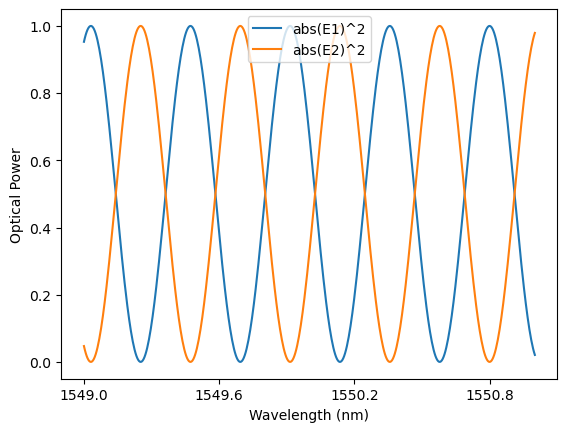

The FSR is 0.4421236658078763 nm


In [1]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

## 1. Give parameters and generate vectors
L = 650e-6    # TBU length
ng = 4.18     # Group index
c = 3e8       # Light speed
Wl = np.linspace(1549,1551,500)*1e-9 #Wavelength
Beta = 2*np.pi*ng/Wl

## 2. Create interferometer
E1 = (1/2)*(np.exp(-1j*Beta*6*L) + np.exp(-1j*Beta*4*L))
E2 = (1/2)*(np.exp(-1j*Beta*6*L) - np.exp(-1j*Beta*4*L))

## 3. Plot Results
fig, ax = plt.subplots()
ax.plot(Wl*1e9, abs(E1)**2)
ax.plot(Wl*1e9, abs(E2)**2)
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.legend(['abs(E1)^2','abs(E2)^2'],loc='upper center')
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Optical Power")
plt.show()

## 4. Check Free Spectral Range
Fsr = (1550e-9)**2/(ng*2*L)
print('The FSR is ' +  str(Fsr*1e9) + ' nm')


We can re-express all the previous calculations as functions of time and frequency, relating lengths and wavelengths to the speed of light and the group index.

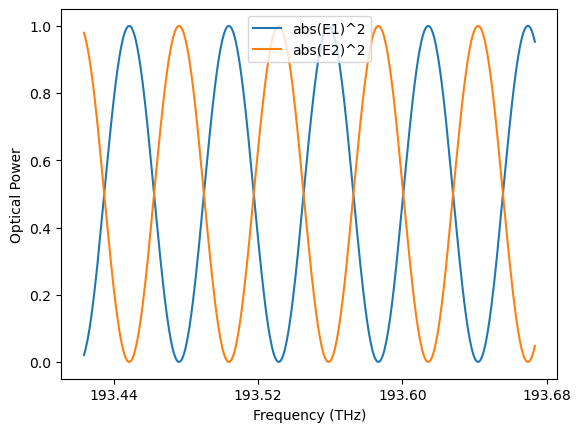

The FSR is 55.207949944792055 GHz


In [2]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

## 1. Give parameters and generate vectors
L = 650e-6    # TBU length
ng = 4.18     # Group index
c = 3e8       # Light speed
T = ng*L/c    # TBU time delay
Wl = np.linspace(1549,1551,500)*1e-9 #Wavelength
f = c/Wl      # Optical frequency 
w = 2*np.pi*f

## 2. Create interferometer
E1 = (1/2)*(np.exp(-1j*w*6*T) + np.exp(-1j*w*4*T))
E2 = (1/2)*(np.exp(-1j*w*6*T) - np.exp(-1j*w*4*T))

## 3. Plot Results
fig, ax = plt.subplots()
ax.plot(f*1e-12, abs(E1)**2)
ax.plot(f*1e-12, abs(E2)**2)
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.legend(['abs(E1)^2','abs(E2)^2'],loc='upper center')
ax.set_xlabel("Frequency (THz)")
ax.set_ylabel("Optical Power")
plt.show()

## 4. Check Free Spectral Range
Fsr = c/(ng*2*L)
print('The FSR is ' +  str(Fsr*1e-9) + ' GHz')

We have indirectly implemented the simplest form of a multi-tap filter based on delay lines, utilizing a single tap of delay (an interferometer). In this example, the implemented delay corresponds to a time difference (ΔT) equal to twice the length of a TBU.

![My Image](Pic2.png)

    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
#    EXCERCISE 1       
--------------------------------------------------------------------------------------------------------------------- 
                                         
    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
        
Recreate the wavelength and frequency response of the multi-tap filter with 2 taps shown below. In your code, include comments indicating the corresponding phase shift angles of the MZIs that form the splitter tree, and label them according to the notation provided in the picture.

![My Image](Pic3.png)

El primer nodo ha de separar 1:2, 1/3 abajo y 2/3 arriba y el segundo nodo ha de separar la potencia por la mitad 1:1. El primer MZI tendrá un ángulo sobre 109º y el segundo MZI 90º.

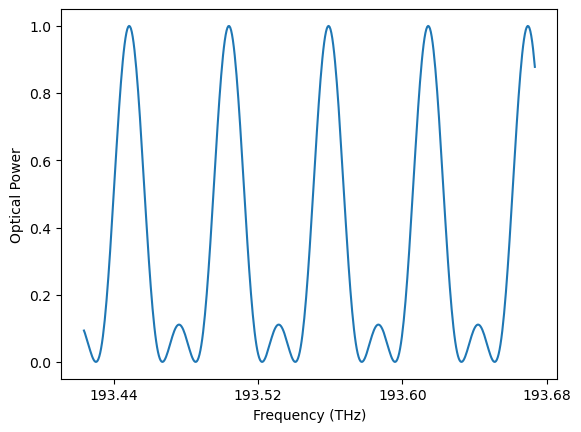

The FSR is 55.207949944792055 GHz


In [3]:
## 1. Give parameters and generate vectors
L = 650e-6    # TBU length
ng = 4.18     # Group index
c = 3e8       # Light speed
T = ng*L/c    # TBU time delay
Wl = np.linspace(1549,1551,500)*1e-9 #Wavelength
f = c/Wl      # Optical frequency 
w = 2*np.pi*f

## 2. Create interferometer
H = 0
for i in range(3):  
    H += (1/3) * np.exp(-1j * i * w * 2 * T)

## 3. Plot Results
fig, ax = plt.subplots()
ax.plot(f*1e-12, abs(H)**2)
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.set_xlabel("Frequency (THz)")
ax.set_ylabel("Optical Power")
plt.show()

## 4. Check Free Spectral Range
Fsr = c/(ng*2*L)
print('The FSR is ' +  str(Fsr*1e-9) + ' GHz')

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%                                       %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

Window functions are crucial in signal processing for mitigating issues related to spectral leakage, designing filters, smoothing data, and analyzing signals in chunks. By applying a window function, you can achieve more accurate and reliable results in various signal processing tasks.

**RECTANGULAR:**<br>
    **Description:** A basic window with constant value within the window and zero outside.<br>
    $$ w(n) = 1 $$
**GAUSSIAN:**<br>
    **Description:** A window shaped like a Gaussian function, useful for applications requiring smooth transitions.<br>
$$ w(n) = exp\left( -\dfrac{1}{2}\left(\dfrac{n - \dfrac{N}{2}}{\sigma \dfrac{N}{2}} \right)^{2}\right) $$
**HAMMING:**<br>
    **Description:** A tapered window function that reduces leakage and provides better frequency resolution.<br>
    $$ w(n) = 0.54 - 0.46\cos(\dfrac{2\pi n}{N}) $$
**HANN:**<br>
    **Description:** Another tapered window function that reduces leakage but with slightly different properties compared to the Hamming window.<br>
$$ w(n) = 0.5(1 - \cos(\dfrac{2\pi n}{N})) $$

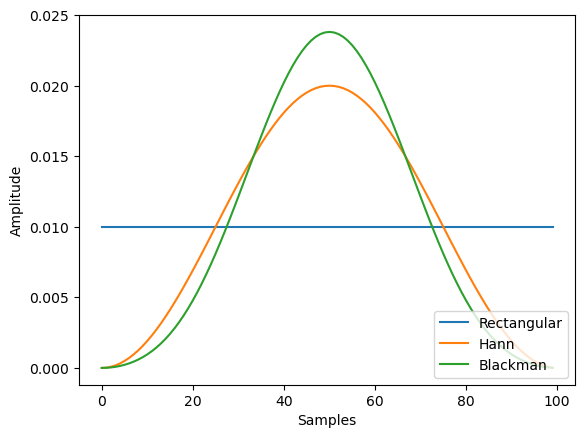

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def Rectangular(N):
    w = np.ones(N)
    w_norm = w/N
    return w_norm

def Hann(N,n):
    w = 0.5*(1 - np.cos(2*np.pi*n/(N)))
    Sum = np.sum(w)
    w_norm = w/Sum
    return w_norm

def Blackman(N,n):
    w = 0.42 - 0.5*np.cos(2*np.pi*n/(N)) + 0.08*np.cos(4*np.pi*n/(N))
    Sum = np.sum(w)
    w_norm = w/Sum
    return w_norm

## 1. Give parameters and generate vectors
N = 100
n = np.arange(0,N)

## 2. Create response
H1 = Rectangular(N)
H2 = Hann(N,n)
H3 = Blackman(N,n)

## 3. Plot Results
fig, ax = plt.subplots()
ax.plot(n, H1)
ax.plot(n, H2)
ax.plot(n, H3)
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.set_xlabel("Samples")
ax.set_ylabel("Amplitude")
ax.legend(['Rectangular','Hann','Blackman'],loc='lower right')
plt.show()

This is especially useful and noteworthy when analyzing the spectral response of signals, particularly when working with a logarithmic scale.

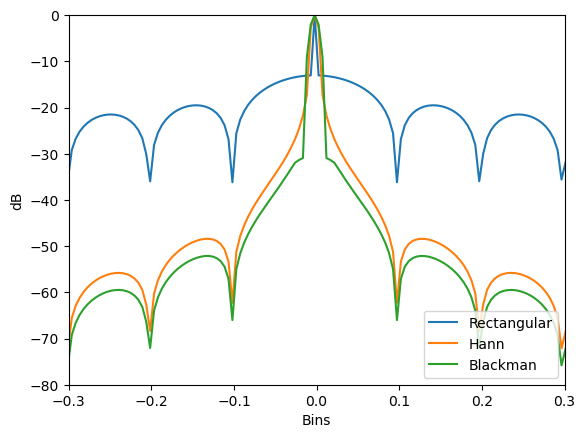

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def Rectangular(N):
    w = np.ones(N)
    w_norm = w/N
    return w_norm

def Hann(N,n):
    w = 0.5*(1 - np.cos(2*np.pi*n/(N)))
    Sum = np.sum(w)
    w_norm = w/Sum
    return w_norm

def Blackman(N,n):
    w = 0.42 - 0.5*np.cos(2*np.pi*n/(N)) + 0.08*np.cos(4*np.pi*n/(N))
    Sum = np.sum(w)
    w_norm = w/Sum
    return w_norm

def Windowing(L,w):
    zeros_before = np.zeros(L)
    zeros_after = np.zeros(L)
    extended_vector = np.concatenate([zeros_before, w, zeros_after])
    return extended_vector

## 1. Give parameters and generate vectors
N = 201
L = 5
n = np.arange(0,N)
n_extended = np.arange(0,N+2*L)
N_ext = len(n_extended)
Bins = np.array(np.arange(-N_ext/2,N_ext/2,1)*(1/N_ext)) 

## 2. Create response
H1 = Rectangular(N)
H2 = Hann(N,n)
H3 = Blackman(N,n)

H1_extended = Windowing(L,H1)
H2_extended = Windowing(L,H2)
H3_extended = Windowing(L,H3)

FFT1 = np.fft.fft(H1_extended)
FFT2 = np.fft.fft(H2_extended)
FFT3 = np.fft.fft(H3_extended)

FFT1_shift = np.fft.fftshift(FFT1)/(max(abs(FFT1)))
FFT2_shift = np.fft.fftshift(FFT2)/(max(abs(FFT2)))
FFT3_shift = np.fft.fftshift(FFT3)/(max(abs(FFT3)))

## 3. Plot Results
fig, ax = plt.subplots()
ax.plot(Bins, 10*np.log10(abs(FFT1_shift)))
ax.plot(Bins, 10*np.log10(abs(FFT2_shift)))
ax.plot(Bins, 10*np.log10(abs(FFT3_shift)))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.set_xlim(-0.3, 0.3 ) 
ax.set_ylim(-80, 0 ) 
ax.set_xlabel("Bins")
ax.set_ylabel("dB")
ax.legend(['Rectangular','Hann','Blackman'],loc='lower right')
plt.show()

    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
    
#  EXCERCISE 2       
---------------------------------------------------------------------------------------------------------------------
                                         
    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
        
Put the window functions into practice. Begin by simulating the response of a lattice filter within the hexagonal mesh using 5 delay taps with uniform input. Next, compare the filter's response when using two different window functions: a Gaussian window and a Sine window.

![My Image](Pic4.png)

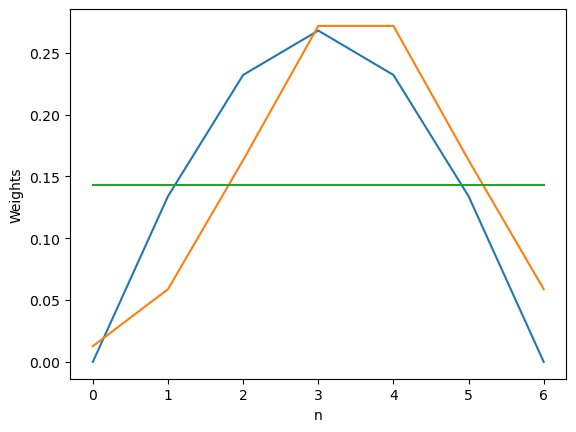

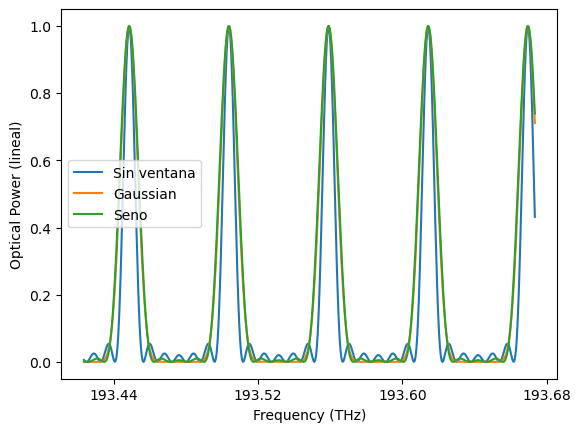

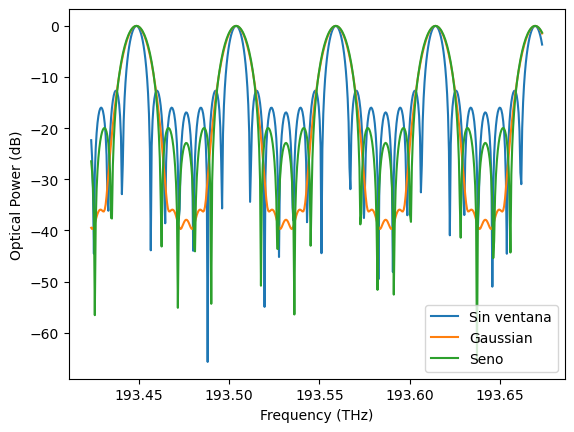

In [20]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def Gaussian(N,n):
    sigma = 0.4
    w = np.exp(-0.5*((n-N/2)/(sigma*N/2))**2)
    Sum = np.sum(w)
    w_norm = w/Sum
    return w_norm

## 1. Give parameters and generate vectors
L = 650e-6    # TBU length
ng = 4.18     # Group index
c = 3e8       # Light speed
T = ng*L/c    # TBU time delay
Wl = np.linspace(1549,1551,500)*1e-9 #Wavelength
f = c/Wl      # Optical frequency 
w = 2*np.pi*f
N = 7
n = np.arange(N)

w_gauss = Gaussian(N,n)
w_rect = Rectangular(N)
w_sine = np.sin(np.pi * n / (N - 1))
w_sine = w_sine / np.sum(w_sine)

## 2. Create interferometer
H = 0
H1 = 0
H2 = 0
for i in range(N):  
    H += w_rect[i] * np.exp(-1j * i * w * 2 * T)
    H1 += w_gauss[i] * np.exp(-1j * i * w * 2 * T)
    H2 += w_sine[i] * np.exp(-1j * i * w * 2 * T)

## 3. Plot Results

fig, ax2 = plt.subplots()
ax2.plot(n, w_sine)
ax2.plot(n, w_gauss)
ax2.plot(n, w_rect)
ax2.set_xlabel('n')
ax2.set_ylabel("Weights")

fig, ax = plt.subplots()
ax.plot(f*1e-12, abs(H)**2, label='Sin ventana')
ax.plot(f*1e-12, abs(H1)**2, label='Gaussian')
ax.plot(f*1e-12, abs(H2)**2, label='Seno')
ax.legend(['Sin ventana','Gaussian', 'Seno'])
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.set_xlabel("Frequency (THz)")
ax.set_ylabel("Optical Power (lineal)")

fig, ax1 = plt.subplots()
ax1.plot(f*1e-12, 10*np.log10(abs(H)**2), label='Sin ventana')
ax1.plot(f*1e-12, 10*np.log10(abs(H1)**2), label='Gaussian')
ax1.plot(f*1e-12, 10*np.log10(abs(H2)**2), label='Seno')
ax1.legend(['Sin ventana','Gaussian', 'Seno'])
ax1.set_xlabel("Frequency (THz)")
ax1.set_ylabel("Optical Power (dB)")
plt.show()


#    III. DELAY LINES BEAMFORMERS      
---------------------------------------------------------------------------------------------------------------------

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%                                       %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

Now, we will explore the final functionality of the delay lines: beamforming networks. In this scenario, independent lines originate from a common tunable splitter, each with a distinct output. Unlike previous cases, the outputs are not combined and each one of them will end in a photodetector and an antenna. 



%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%                                       %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

![My Image](Pic5.png)
![My Image](Pic6.png)

    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

#     EXCERCISE 3       
---------------------------------------------------------------------------------------------------------------------
                                         
    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
        
In this final exercise, we aim to design a beamforming network using a large, newly developed hexagonal programmable mesh. Since this mesh has not yet been fabricated, we must define the length of the TBU to meet the requirements of our beamforming network (BFN). The only constraints we have are that we have 8 antennas, the antennas' maximum frequency is 25 GHz, we only need a maximum pointing range at 60º, and the array will have 8 distinct positions, ranging from ΔT = 0 TBU to ΔT = 14 TBU in steps of 2 TBU.

**1.** Find the max separation between antennas of the array.<br>
**2.** Find the length of the TBU for a maximum pointing angle of 60º.<br>
**3.** Plot all the possible pointing angles for 25 GHz and 15 GHz using a polar plot. <br>
**4.** Plot all the main angle (0º,ΔT = 0 TBU ) at 25 GHz for uniform feeding and for gaussian apodization. <br>



1. calcular d (6 mm)
2. sacar deltaT con formula recuadrada (1.23 ps)
3. Implementar el Uniform feeding condition (88.79 um)

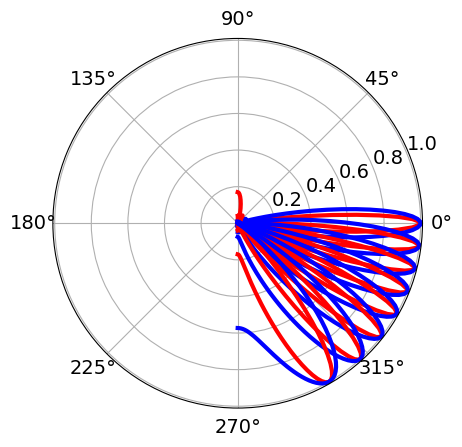

In [33]:
angle = np.linspace(-np.pi/2, np.pi/2, 200)
c = 3e8
ng = 4.18
N = 10
fmax = 25e9

d = c/(2 * fmax)
T = (d/c) * np.sin(60 * np.pi/180) * (1/14)
L = c * T/ng

f = 25e9
w = 2 * np.pi * f
f1 = 15e9
w1 = 2 * np.pi * f1
fig,ax = plt.subplots(subplot_kw={'projection': 'polar'})
for p in range(0,8):
    F, F1 = 0, 0
    for k in range(0,N):
        F += (1/N) * np.exp(1j * w * k * ((d/c) * np.sin(angle) + p * 2 * T))
        F1 += (1/N) * np.exp(1j * w1 * k * ((d/c) * np.sin(angle) + p * 2 * T))
    ax.plot(angle, (abs(F)**2),color='red',lw=3)
    ax.plot(angle, (abs(F1)**2),color='blue',lw=3)
ax.set_rmax(1.01)
ax.tick_params(axis='both', labelsize=14)
plt.show()
